In [ ]:
!pip install importlib_resources

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import os
import numpy as np

print("Loading dataset using TensorFlow Datasets...")

# TFDS থেকে cats_vs_dogs ডেটাসেটের ছোট একটি অংশ লোড করা
(ds_train,), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:200]'], # মোট ২০০টি ছবি নেব (১০০টি বিড়াল, ১০০টি কুকুর)
    as_supervised=True,
    with_info=True
)

# নতুন ফোল্ডার তৈরি
TARGET_DIR = '/content/Small_Dataset'
os.makedirs(os.path.join(TARGET_DIR, 'Class_0'), exist_ok=True) # Cats
os.makedirs(os.path.join(TARGET_DIR, 'Class_1'), exist_ok=True) # Dogs

cat_count = 0
dog_count = 0

for i, (image, label) in enumerate(ds_train):
    img = tf.image.resize(image, (128, 128))
    img = tf.cast(img, tf.uint8)
    encoded_img = tf.image.encode_jpeg(img)

    # label == 0 হলো cat, label == 1 হলো dog
    if label == 0 and cat_count < 100:
        path = os.path.join(TARGET_DIR, 'Class_0', f'cat_{cat_count}.jpg')
        tf.io.write_file(path, encoded_img)
        cat_count += 1
    elif label == 1 and dog_count < 100:
        path = os.path.join(TARGET_DIR, 'Class_1', f'dog_{dog_count}.jpg')
        tf.io.write_file(path, encoded_img)
        dog_count += 1

    if cat_count >= 100 and dog_count >= 100:
        break

print(f"Dataset successfully created!")
print(f"Total Cats saved: {cat_count}")
print(f"Total Dogs saved: {dog_count}")
print(f"Dataset Path: {TARGET_DIR}")

Loading dataset using TensorFlow Datasets...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.KEERAI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset successfully created!
Total Cats saved: 100
Total Dogs saved: 97
Dataset Path: /content/Small_Dataset


In [ ]:
import tensorflow as tf

DATA_DIR = '/content/Small_Dataset'
BATCH_SIZE = 16  # যেহেতু ছোট ডেটাসেট (২০০ ছবি), ব্যাচ সাইজ ১৬ রাখা ভালো

# --- Custom CNN এর জন্য ডেটা লোড (128x128) ---
IMG_SIZE_CNN = (128, 128)

train_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=123,
    image_size=IMG_SIZE_CNN, batch_size=BATCH_SIZE, label_mode='binary'
)
val_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=123,
    image_size=IMG_SIZE_CNN, batch_size=BATCH_SIZE, label_mode='binary'
)

# Rescaling [0, 1]
norm_layer = tf.keras.layers.Rescaling(1./255)
train_ds_cnn = train_ds_cnn.map(lambda x, y: (norm_layer(x), y))
val_ds_cnn = val_ds_cnn.map(lambda x, y: (norm_layer(x), y))


# --- VGG19 এর জন্য ডেটা লোড (224x224) ---
IMG_SIZE_VGG = (224, 224)

train_ds_vgg = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=123,
    image_size=IMG_SIZE_VGG, batch_size=BATCH_SIZE, label_mode='binary'
)
val_ds_vgg = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=123,
    image_size=IMG_SIZE_VGG, batch_size=BATCH_SIZE, label_mode='binary'
)

# VGG19 Preprocessing
vgg_preprocess = tf.keras.applications.vgg19.preprocess_input
train_ds_vgg = train_ds_vgg.map(lambda x, y: (vgg_preprocess(x), y))
val_ds_vgg = val_ds_vgg.map(lambda x, y: (vgg_preprocess(x), y))

# Performance Optimization
AUTOTUNE = tf.data.AUTOTUNE
train_ds_cnn = train_ds_cnn.prefetch(buffer_size=AUTOTUNE)
val_ds_cnn = val_ds_cnn.prefetch(buffer_size=AUTOTUNE)
train_ds_vgg = train_ds_vgg.prefetch(buffer_size=AUTOTUNE)
val_ds_vgg = val_ds_vgg.prefetch(buffer_size=AUTOTUNE)

print("Data loaded successfully!")

Found 197 files belonging to 2 classes.
Using 158 files for training.
Found 197 files belonging to 2 classes.
Using 39 files for validation.
Found 197 files belonging to 2 classes.
Using 158 files for training.
Found 197 files belonging to 2 classes.
Using 39 files for validation.
Data loaded successfully!


In [ ]:
import time

model_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

start_time_cnn = time.time()
history_cnn = model_cnn.fit(train_ds_cnn, validation_data=val_ds_cnn, epochs=10)
train_time_cnn = time.time() - start_time_cnn
print(f"Custom CNN Training Time: {train_time_cnn:.2f} seconds")

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 799ms/step - accuracy: 0.5443 - loss: 0.8128 - val_accuracy: 0.5128 - val_loss: 0.6920
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 518ms/step - accuracy: 0.5253 - loss: 0.6860 - val_accuracy: 0.4615 - val_loss: 0.6996
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 511ms/step - accuracy: 0.6329 - loss: 0.6667 - val_accuracy: 0.5128 - val_loss: 0.6958
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 729ms/step - accuracy: 0.6519 - loss: 0.6351 - val_accuracy: 0.5128 - val_loss: 0.7154
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 487ms/step - accuracy: 0.6899 - loss: 0.5710 - val_accuracy: 0.6154 - val_loss: 0.6575
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 735ms/step - accuracy: 0.7152 - loss: 0.5134 - val_accuracy: 0.5385 - val_loss: 0.6754
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 545ms/step - accuracy: 0.8165 - loss: 0.3893 - val_accuracy: 0.5897 - val_loss: 0.8462
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 493ms/step - accuracy: 0.8797 - loss: 0.2974 - val_accuracy: 0.

In [ ]:
base_model = tf.keras.applications.VGG19(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model_vgg = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_vgg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

start_time_vgg = time.time()
history_vgg = model_vgg.fit(train_ds_vgg, validation_data=val_ds_vgg, epochs=10)
train_time_vgg = time.time() - start_time_vgg
print(f"VGG19 Training Time: {train_time_vgg:.2f} seconds")

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 184s 19s/step - accuracy: 0.5316 - loss: 1.9768 - val_accuracy: 0.7692 - val_loss: 0.5290
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 194s 18s/step - accuracy: 0.6582 - loss: 1.1765 - val_accuracy: 0.9231 - val_loss: 0.2415
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 186s 19s/step - accuracy: 0.7468 - loss: 0.7912 - val_accuracy: 0.9744 - val_loss: 0.1579
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 172s 18s/step - accuracy: 0.7215 - loss: 0.7768 - val_accuracy: 0.9487 - val_loss: 0.1344
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 173s 18s/step - accuracy: 0.8291 - loss: 0.4403 - val_accuracy: 0.9487 - val_loss: 0.1034
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 179s 18s/step - accuracy: 0.8228 - loss: 0.4836 - val_accuracy: 0.9744 - val_loss: 0.0696
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 180s 18s/step - accuracy: 0.8544 - loss: 0.3260 - val_accuracy: 0.9744 - val_loss: 0.0609
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 200s 18s/step -

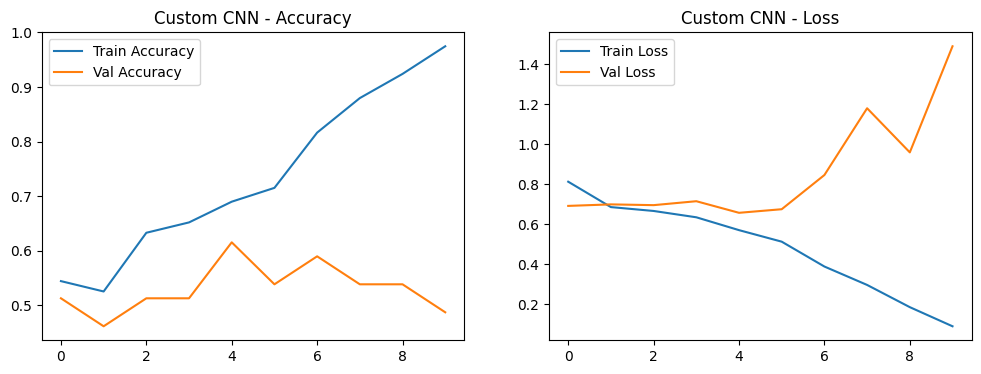

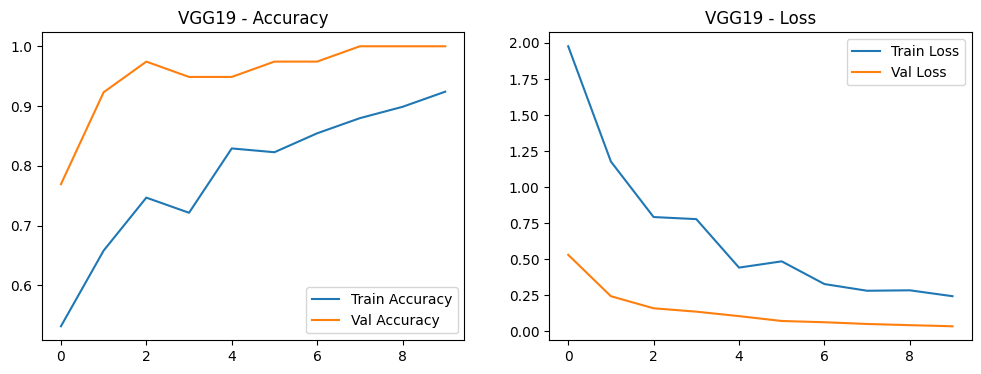

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Train Accuracy')
    plt.plot(epochs, val_acc, label='Val Accuracy')
    plt.title(f'{model_name} - Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.title(f'{model_name} - Loss')
    plt.legend()
    plt.show()

plot_history(history_cnn, "Custom CNN")
plot_history(history_vgg, "VGG19")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 504ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 589ms/step
=== Custom CNN Evaluation Report ===
               precision    recall  f1-score   support

Cat (Class 0)       0.47      0.47      0.47        19
Dog (Class 1)       0.50      0.50      0.50        20

     accuracy                           0.49        39
    macro avg       0.49      0.49      0.49        39
 weighted avg       0.49      0.49      0.49        39



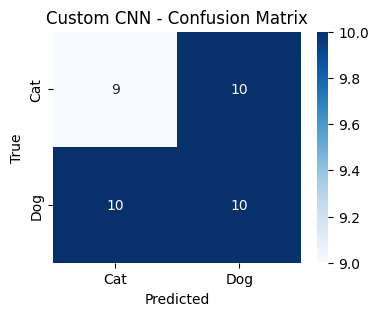

1/1 ━━━━━━━━━━━━━━━━━━━━ 21s 21s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
=== VGG19 Transfer Learning Evaluation Report ===
               precision    recall  f1-score   support

Cat (Class 0)       1.00      1.00      1.00        19
Dog (Class 1)       1.00      1.00      1.00        20

     accuracy                           1.00        39
    macro avg       1.00      1.00      1.00        39
 weighted avg       1.00      1.00      1.00        39



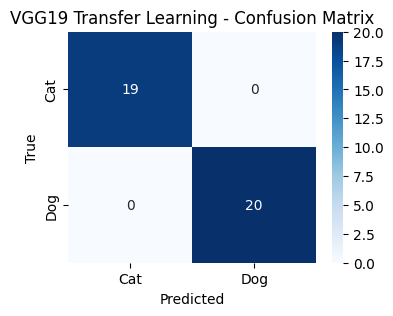

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(model, val_ds, model_name):
    y_true = []
    y_pred_probs = []

    for images, labels in val_ds:
        preds = model.predict(images)
        y_true.extend(labels.numpy().flatten())
        y_pred_probs.extend(preds.flatten())

    y_pred = (np.array(y_pred_probs) >= 0.5).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    print(f"=== {model_name} Evaluation Report ===")
    print(classification_report(y_true, y_pred, target_names=['Cat (Class 0)', 'Dog (Class 1)']))

    # Confusion Matrix Plot
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cat', 'Dog'], yticklabels=['Cat', 'Dog'])
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

# Custom CNN ও VGG19 দুটোই চেক করুন
evaluate_model(model_cnn, val_ds_cnn, "Custom CNN")
evaluate_model(model_vgg, val_ds_vgg, "VGG19 Transfer Learning")

In [ ]:
import pandas as pd

# Apnar prapto asol man gulo diye table toiri korchi
data = {
    "Evaluation Metrics": ["Test Accuracy", "Precision (Cat)", "Precision (Dog)", "Recall (Cat)", "Recall (Dog)", "F1-Score (Cat)", "F1-Score (Dog)"],
    "Custom CNN": [0.49, 0.47, 0.50, 0.47, 0.50, 0.47, 0.50],
    "VGG19 Transfer Learning": [1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00]
}

df = pd.DataFrame(data)
display(df)

,Evaluation Metrics,Custom CNN,VGG19 Transfer Learning
0,Test Accuracy,0.49,1.0
1,Precision (Cat),0.47,1.0
2,Precision (Dog),0.50,1.0
3,Recall (Cat),0.47,1.0
4,Recall (Dog),0.50,1.0
5,F1-Score (Cat),0.47,1.0
6,F1-Score (Dog),0.50,1.0


1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step


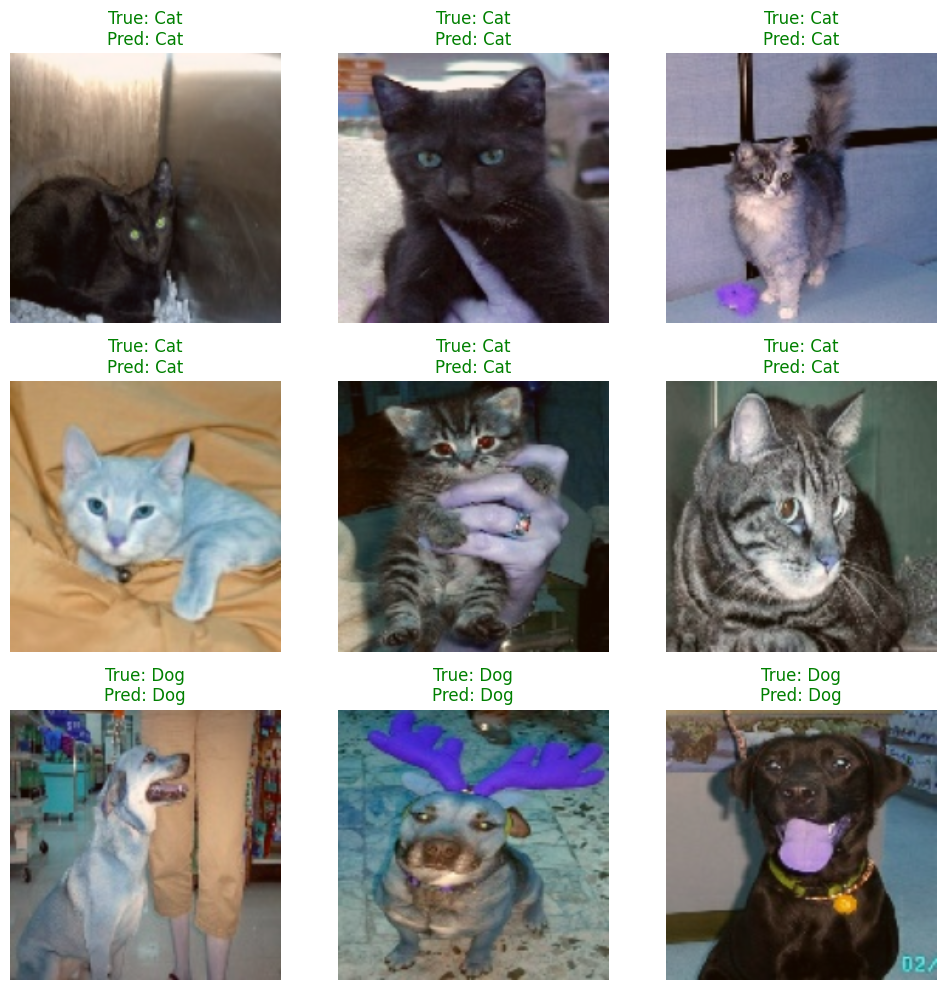

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# VGG19 এর টেস্ট ডেটা থেকে এক ব্যাচ ছবি ও লেবেল নেওয়া
for images, labels in val_ds_vgg.take(1):
    preds = model_vgg.predict(images)
    pred_labels = (preds >= 0.5).astype(int).flatten()
    true_labels = labels.numpy().flatten()

    plt.figure(figsize=(10, 10))
    for i in range(min(9, len(images))):  # সর্বোচ্চ ৯টি ছবি দেখাবে
        plt.subplot(3, 3, i + 1)

        # ছবি নরমালাইজেশন ঠিক করা (VGG preprocess റിവേഴ്স বা নরমাল দেখানোর জন্য)
        img = images[i].numpy()
        img = (img - img.min()) / (img.max() - img.min()) # Normalize to [0, 1] for display

        plt.imshow(img)

        pred_class = "Dog" if pred_labels[i] == 1 else "Cat"
        true_class = "Dog" if true_labels[i] == 1 else "Cat"

        color = "green" if pred_labels[i] == true_labels[i] else "red"
        plt.title(f"True: {true_class}\nPred: {pred_class}", color=color)
        plt.axis('off')

    plt.tight_layout()
    plt.show()